# CompuOpti: multi-objective staff scheduling with OR-Tools CP-SAT

Decision Modelling project (CentraleSupélec). Everything is in this notebook: data, an independent
checker, the CP-SAT model, two exact Pareto methods, plots in objective and decision space, and an
instance generator.

**Run:** `uv run jupyter lab CompuOpti_staffing.ipynb`, then *Run all*. With the default budgets the
notebook takes about 15 minutes. Raise `BUDGET` to get more medium/large points proven.

In [1]:
import contextlib
import itertools
import json
import os
import random
import time
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd
from ipywidgets import interact
from ortools.sat.python import cp_model

TL, BUDGET = 10, 120  # seconds per solve, seconds per Pareto front
WORKERS = os.cpu_count() or 4  # use every core (an 8-thread setting on a 2-core box only adds overhead)
OBJS = ["profit", "duration", "projects_per_staff", "late_jobs", "team_size", "imbalance"]
BRIEF = OBJS[:4]  # the brief's four objectives; the last two are our extras
BLUE, LIGHT, ORANGE, GREY = "#2a78d6", "#9ec5f4", "#ec835a", "#e1e0d9"

## 1. Data, read as a real staffing problem

* Each employee-day goes to one (project, qualification) pair, or stays idle.
* **A rejected project gets no work at all.** Nobody half-staffs a project that won't be delivered,
  so coverage is an equality: a project is either fully staffed or untouched.
* **Duration is the calendar span** from a project's first to last working day, including holiday
  gaps, because that is the wait the client sees.
* **Only delivered projects can be late.** A dropped project counts as declined, not late.
* All three instances need more person-days than the staff have (demand/capacity > 1), so the real
  decision is *which projects to accept*.

In [2]:
def prepare(d, name="generated"):
    """Index staff/jobs by name and list the legal (staff, job, qual, day) slots."""
    d["name"], d["days"] = name, range(1, d["horizon"] + 1)
    d["S"] = {s["name"]: s for s in d["staff"]}
    d["J"] = {j["name"]: j for j in d["jobs"]}
    for j in d["jobs"]:
        j["req"] = j["working_days_per_qualification"]
    d["slots"] = [
        (s["name"], j["name"], q, t)
        for s in d["staff"]
        for j in d["jobs"]
        for q in j["req"]
        if q in s["qualifications"]
        for t in d["days"]
        if t not in s["vacations"]
    ]
    return d

In [3]:
"""The three course instances, embedded so the notebook runs even without the Datasets/ folder."""
EMBEDDED = {"toy":{"horizon":5,"qualifications":["A","B","C"],"staff":[{"name":"Olivia","qualifications":["A","B","C"],"vacations":[]},{"name":"Liam","qualifications":["A","B"],"vacations":[1]},{"name":"Emma","qualifications":["C"],"vacations":[2]}],"jobs":[{"name":"Job1","gain":20,"due_date":3,"daily_penalty":3,"working_days_per_qualification":{"A":1,"B":1,"C":1}},{"name":"Job2","gain":15,"due_date":3,"daily_penalty":3,"working_days_per_qualification":{"A":1,"B":2}},{"name":"Job3","gain":15,"due_date":4,"daily_penalty":3,"working_days_per_qualification":{"A":1,"C":2}},{"name":"Job4","gain":20,"due_date":3,"daily_penalty":3,"working_days_per_qualification":{"B":2,"C":1}},{"name":"Job5","gain":10,"due_date":5,"daily_penalty":3,"working_days_per_qualification":{"C":2}}]},"medium":{"horizon":22,"qualifications":["F","G","A","D","J","C","H","E","B","I"],"staff":[{"name":"Olivia","qualifications":["A","B","C"],"vacations":[1,2]},{"name":"Liam","qualifications":["A","D","E"],"vacations":[1,2]},{"name":"Emma","qualifications":["B","H"],"vacations":[8,9]},{"name":"Noah","qualifications":["G","D","J","C","H","I"],"vacations":[]},{"name":"Amelia","qualifications":["F","G","J","E"],"vacations":[16,15]}],"jobs":[{"name":"Job1","gain":15,"due_date":20,"daily_penalty":3,"working_days_per_qualification":{"A":4,"B":4}},{"name":"Job2","gain":30,"due_date":16,"daily_penalty":3,"working_days_per_qualification":{"A":4,"B":2,"C":1,"D":4}},{"name":"Job3","gain":30,"due_date":12,"daily_penalty":3,"working_days_per_qualification":{"A":4,"C":1}},{"name":"Job4","gain":30,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"A":6}},{"name":"Job5","gain":70,"due_date":10,"daily_penalty":3,"working_days_per_qualification":{"B":3,"C":4,"D":8}},{"name":"Job6","gain":40,"due_date":16,"daily_penalty":3,"working_days_per_qualification":{"D":4,"E":5}},{"name":"Job7","gain":20,"due_date":20,"daily_penalty":3,"working_days_per_qualification":{"D":5,"E":5,"F":1}},{"name":"Job8","gain":10,"due_date":22,"daily_penalty":3,"working_days_per_qualification":{"E":3,"F":6}},{"name":"Job9","gain":25,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"E":4,"G":3,"H":2}},{"name":"Job10","gain":20,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"F":6}},{"name":"Job11","gain":25,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"F":6,"G":2,"H":1}},{"name":"Job12","gain":45,"due_date":12,"daily_penalty":3,"working_days_per_qualification":{"H":6,"J":3}},{"name":"Job13","gain":40,"due_date":14,"daily_penalty":3,"working_days_per_qualification":{"I":4,"J":8}},{"name":"Job14","gain":60,"due_date":12,"daily_penalty":3,"working_days_per_qualification":{"G":4,"J":4}},{"name":"Job15","gain":50,"due_date":16,"daily_penalty":3,"working_days_per_qualification":{"G":4,"H":4}}]},"large":{"horizon":36,"qualifications":["E","I","J","A","C","H","G","D","B","F"],"staff":[{"name":"Olivia","qualifications":["B","A","C"],"vacations":[1,2,3,4,5]},{"name":"Liam","qualifications":["E","A","D"],"vacations":[6,7,8,9,10]},{"name":"Emma","qualifications":["B","H"],"vacations":[21,22,23,24,25]},{"name":"Noah","qualifications":["C","H","G","D"],"vacations":[26,27,28,29,30]},{"name":"Amelia","qualifications":["E","I","G","J","F"],"vacations":[]},{"name":"Oliver","qualifications":["J","F","G"],"vacations":[32,33,31]}],"jobs":[{"name":"Job1","gain":15,"due_date":26,"daily_penalty":3,"working_days_per_qualification":{"A":4,"B":4}},{"name":"Job2","gain":30,"due_date":22,"daily_penalty":3,"working_days_per_qualification":{"A":4,"B":2,"C":1,"D":4}},{"name":"Job3","gain":30,"due_date":16,"daily_penalty":3,"working_days_per_qualification":{"A":4,"C":1}},{"name":"Job4","gain":30,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"A":6}},{"name":"Job6","gain":70,"due_date":14,"daily_penalty":3,"working_days_per_qualification":{"B":3,"C":4,"D":8}},{"name":"Job7","gain":50,"due_date":32,"daily_penalty":3,"working_days_per_qualification":{"B":3,"E":4,"H":7}},{"name":"Job8","gain":50,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"B":3,"I":4}},{"name":"Job9","gain":80,"due_date":30,"daily_penalty":3,"working_days_per_qualification":{"C":5,"D":5,"G":8}},{"name":"Job10","gain":80,"due_date":20,"daily_penalty":3,"working_days_per_qualification":{"C":7,"F":5,"H":8}},{"name":"Job11","gain":20,"due_date":32,"daily_penalty":3,"working_days_per_qualification":{"C":4,"I":5}},{"name":"Job12","gain":20,"due_date":32,"daily_penalty":3,"working_days_per_qualification":{"C":8,"J":4}},{"name":"Job13","gain":40,"due_date":26,"daily_penalty":3,"working_days_per_qualification":{"D":4,"E":5}},{"name":"Job14","gain":20,"due_date":30,"daily_penalty":3,"working_days_per_qualification":{"D":5,"E":5,"F":1}},{"name":"Job15","gain":20,"due_date":26,"daily_penalty":3,"working_days_per_qualification":{"D":5,"G":5,"J":3}},{"name":"Job16","gain":20,"due_date":36,"daily_penalty":3,"working_days_per_qualification":{"D":5,"H":5,"J":2}},{"name":"Job17","gain":80,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"E":3,"F":6,"I":8}},{"name":"Job18","gain":25,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"E":4,"G":3,"H":2}},{"name":"Job20","gain":20,"due_date":26,"daily_penalty":3,"working_days_per_qualification":{"F":6}},{"name":"Job21","gain":25,"due_date":18,"daily_penalty":3,"working_days_per_qualification":{"F":6,"G":2,"H":1}},{"name":"Job22","gain":60,"due_date":12,"daily_penalty":3,"working_days_per_qualification":{"G":4,"H":4}},{"name":"Job23","gain":50,"due_date":28,"daily_penalty":3,"working_days_per_qualification":{"G":4,"I":6,"J":4}},{"name":"Job24","gain":50,"due_date":26,"daily_penalty":3,"working_days_per_qualification":{"G":4,"J":4}},{"name":"Job25","gain":45,"due_date":12,"daily_penalty":3,"working_days_per_qualification":{"H":6,"I":3}},{"name":"Job27","gain":40,"due_date":14,"daily_penalty":3,"working_days_per_qualification":{"I":4,"J":8}},{"name":"Job28","gain":50,"due_date":14,"daily_penalty":3,"working_days_per_qualification":{"J":10}}]}}


def load_instance(name):
    """Course JSON file if present (Datasets/ or the current folder), otherwise the embedded copy."""
    for p in (Path("Datasets") / f"{name}_instance.json", Path(f"{name}_instance.json")):
        if p.exists():
            return json.loads(p.read_text())
    return json.loads(json.dumps(EMBEDDED[name]))


def stats(I):
    cap = sum(I["horizon"] - len(s["vacations"]) for s in I["staff"])
    demand = sum(sum(j["req"].values()) for j in I["jobs"])
    return {
        "days": I["horizon"],
        "staff": len(I["staff"]),
        "jobs": len(I["jobs"]),
        "x variables": len(I["slots"]),
        "demand / capacity": round(demand / cap, 2),
    }


INST = {
    n: prepare(load_instance(n), n)
    for n in ["toy", "medium", "large"]
}
pd.DataFrame({n: stats(I) for n, I in INST.items()})

,toy,medium,large
days,5.00,22.00,36.00
staff,3.00,5.00,6.00
jobs,5.00,15.00,25.00
x variables,90.00,1298.00,3939.00
demand / capacity,1.08,1.32,1.41


## 2. Independent checker

A schedule is a dict `{(employee, day): (job, qualification)}`, so "one task per day" holds by
construction. Every number in this notebook comes from `evaluate`, never from the solver's own
variables. That way a modelling mistake can't hide.

In [4]:
def utilisation(I, sched):
    """% of available days worked, for staff who could work on at least one job."""
    load = defaultdict(int)
    for i, _ in sched:
        load[i] += 1
    needed = {q for j in I["jobs"] for q in j["req"]}
    return {
        s["name"]: 100 * load[s["name"]] // (I["horizon"] - len(s["vacations"]))
        for s in I["staff"]
        if needed & set(s["qualifications"]) and len(s["vacations"]) < I["horizon"]
    }

In [5]:
def evaluate(I, sched):
    """Check every hard rule, then compute the six objectives."""
    work = defaultdict(lambda: defaultdict(int))
    days, team, jobs_of = defaultdict(set), defaultdict(set), defaultdict(set)
    for (i, t), (j, q) in sched.items():
        s = I["S"][i]
        assert q in s["qualifications"] and q in I["J"][j]["req"], "skill rule"
        assert t in I["days"] and t not in s["vacations"], "holiday rule"
        work[j][q] += 1
        days[j].add(t)
        team[j].add(i)
        jobs_of[i].add(j)
    assert all(work[j] == I["J"][j]["req"] for j in work), "a job is partly or over-staffed"
    late = {j: max(0, max(days[j]) - I["J"][j]["due_date"]) for j in work}
    util = utilisation(I, sched).values()
    return {
        "profit": sum(I["J"][j]["gain"] - I["J"][j]["daily_penalty"] * late[j] for j in work),
        "duration": max((max(d) - min(d) + 1 for d in days.values()), default=0),
        "projects_per_staff": max(map(len, jobs_of.values()), default=0),
        "late_jobs": sum(v > 0 for v in late.values()),
        "team_size": max(map(len, team.values()), default=0),
        "imbalance": max(util, default=0) - min(util, default=0),
    }

In [6]:
evaluate(INST["toy"], {})  # doing nothing: feasible, every objective 0

{'profit': 0,
 'duration': 0,
 'projects_per_staff': 0,
 'late_jobs': 0,
 'team_size': 0,
 'imbalance': 0}

## 3. The CP-SAT model

| symbol | meaning |
|---|---|
| $x_{i,j,k,t}\in\{0,1\}$ | employee $i$ works on qualification $k$ of job $j$ on day $t$ (created only if $i$ has $k$, $j$ needs $k$, and $t$ is not a holiday) |
| $y_j\in\{0,1\}$ | job $j$ is delivered |
| $a_{j,t}, b_{j,t}, w_{j,t}$ | job $j$ has started by day $t$ / is still open on day $t$ / day $t$ is inside its window |

**Constraints:** $\sum_{j,k}x_{i,j,k,t}\le 1$ (one task per day), and $\sum_{i,t}x_{i,j,k,t}=n_{j,k}\,y_j$
(all or nothing, at most once). Work happens only inside the window: $x\le w$. Then
$\text{span}_j=\sum_t w_{j,t}$ and $\text{late days}_j=\sum_{t>d_j}b_{j,t}$.

| | objective | sense | why it matters |
|---|---|---|---|
| f1 | profit $=\sum g_j y_j-\sum c_j\,\text{late days}_j$ | max | the brief |
| f2 | longest project span | min | the brief: deliver fast |
| f3 | most projects any one employee works on | min | the brief: less context switching |
| f4 | number of late projects | min | the brief: reputation |
| E1 | largest team on a project | min | extra: coordination cost (meetings, hand-overs) |
| E2 | utilisation gap max − min, as % of available days | min | extra: fairness, as % so holidays don't count as idleness |

In [7]:
def group(d, key):
    out = defaultdict(list)
    for k, v in d.items():
        out[key(k)].append(v)
    return out

In [8]:
def add_core(M, I):
    m = M.m
    M.x = {s: m.new_bool_var("") for s in I["slots"]}  # skill + holiday rules by construction
    M.y = {j: m.new_bool_var("") for j in I["J"]}
    for xs in group(M.x, lambda s: (s[0], s[3])).values():
        m.add_at_most_one(xs)  # one task per employee per day
    cover = group(M.x, lambda s: (s[1], s[2]))
    for j, job in I["J"].items():
        for q, n in job["req"].items():
            m.add(sum(cover[j, q]) == n * M.y[j])  # all or nothing

In [9]:
def add_windows(M, I):
    m, h = M.m, I["horizon"]
    M.a, M.b, M.w = ({j: [m.new_bool_var("") for _ in I["days"]] for j in I["J"]} for _ in "abw")
    for j in I["J"]:
        a, b, w = M.a[j], M.b[j], M.w[j]
        for t in range(h - 1):
            m.add_implication(a[t], a[t + 1])  # once started, stays started
            m.add_implication(b[t + 1], b[t])  # once closed, stays closed
        for t in range(h):
            m.add_bool_and([a[t], b[t]]).only_enforce_if(w[t])  # w = a AND b
            m.add_bool_or([w[t], a[t].Not(), b[t].Not()])
            m.add_implication(w[t], M.y[j])
    for (_, j, t), xs in group(M.x, lambda s: s[:2] + s[3:]).items():
        m.add(sum(xs) <= M.w[j][t - 1])  # work only inside the window
    M.late_days = {
        j: sum(M.b[j][job["due_date"] :]) for j, job in I["J"].items() if job["due_date"] < h
    }

In [10]:
def hall_data(I, max_all=12):
    """Every skill subset S with the number of employee-days able to work on at least one skill of S."""
    Q = sorted({q for j in I["jobs"] for q in j["req"]})
    sizes = range(1, len(Q) + 1) if len(Q) <= max_all else range(1, 4)
    subsets = [set(S) for r in sizes for S in itertools.combinations(Q, r)]
    avail = {s["name"]: I["horizon"] - len(s["vacations"]) for s in I["staff"]}
    quals = {s["name"]: set(s["qualifications"]) for s in I["staff"]}
    return subsets, [sum(avail[i] for i in quals if quals[i] & S) for S in subsets]


def add_cuts(M, I):
    """Valid inequalities: they only speed the solver up.
    Hall cuts: for every skill subset S, the demand of the delivered jobs in S fits in the days of the
    employees who hold at least one skill of S. (Hall's theorem: these are also *sufficient* for staffing a
    set of jobs when due dates are ignored.)"""
    for S, cap in zip(*hall_data(I)):
        load = [(sum(n for q, n in j["req"].items() if q in S), j["name"]) for j in I["jobs"]]
        if sum(c for c, _ in load) > cap:
            M.m.add(sum(c * M.y[n] for c, n in load if c) <= cap)
    for j, job in I["J"].items():
        holders = {q: [s for s in I["staff"] if q in s["qualifications"]] for q in job["req"]}
        span = max(-(-n // max(1, len(holders[q]))) for q, n in job["req"].items())
        M.m.add(sum(M.w[j]) >= span * M.y[j])

Each objective gets one integer variable $v$, linked in one direction only ($v\ge$ true value
for a minimised objective). Optimising, bounding or excluding $v$ is still exact, because the true
values are always a feasible choice of $v$. Reported values come from `evaluate`.

In [11]:
def new_objective(M, name, lo, hi):
    M.v[name], M.dom[name] = M.m.new_int_var(lo, hi, name), (lo, hi)
    return M.v[name]


def f_profit(M, I):
    J, h = I["J"], I["horizon"]
    worst = sum(J[j]["daily_penalty"] * (h - J[j]["due_date"]) for j in M.late_days)
    v = new_objective(M, "profit", -worst, sum(j["gain"] for j in I["jobs"]))
    gains = sum(J[j]["gain"] * M.y[j] for j in J)
    M.m.add(v == gains - sum(J[j]["daily_penalty"] * ld for j, ld in M.late_days.items()))

In [12]:
def f_duration(M, I):
    v = new_objective(M, "duration", 0, I["horizon"])
    for w in M.w.values():
        M.m.add(v >= sum(w))


def f_late_jobs(M, I):
    late = [M.b[j][I["J"][j]["due_date"]] for j in M.late_days]  # still open the day after d_j
    M.m.add(new_objective(M, "late_jobs", 0, len(late)) == sum(late))

In [13]:
def works_on(M):
    """u[i, j] = 1 if employee i does any work on job j."""
    if not hasattr(M, "u"):
        M.u = {k: M.m.new_bool_var("") for k in group(M.x, lambda s: s[:2])}
        for s, x in M.x.items():
            M.m.add_implication(x, M.u[s[:2]])
    return M.u


def f_projects_per_staff(M, I):
    v = new_objective(M, "projects_per_staff", 0, len(I["jobs"]))
    for us in group(works_on(M), lambda k: k[0]).values():
        M.m.add(v >= sum(us))


def f_team_size(M, I):
    v = new_objective(M, "team_size", 0, len(I["staff"]))
    for us in group(works_on(M), lambda k: k[1]).values():
        M.m.add(v >= sum(us))

In [14]:
def f_imbalance(M, I):
    hi, lo, load = (
        M.m.new_int_var(0, 100, ""),
        M.m.new_int_var(0, 100, ""),
        group(M.x, lambda s: s[0]),
    )
    for i in utilisation(I, {}):  # staff who can contribute
        u = M.m.new_int_var(0, 100, "")
        M.m.add_division_equality(u, 100 * sum(load[i]), I["horizon"] - len(I["S"][i]["vacations"]))
        M.m.add(hi >= u)
        M.m.add(lo <= u)
    M.m.add(new_objective(M, "imbalance", 0, 100) == hi - lo)

In [15]:
def build(I, objs):
    M = SimpleNamespace(m=cp_model.CpModel(), v={}, dom={})
    add_core(M, I)
    add_windows(M, I)
    add_cuts(M, I)
    for o in objs:
        OBJECTIVE[o](M, I)
    return M


OBJECTIVE = {
    "profit": f_profit,
    "duration": f_duration,
    "projects_per_staff": f_projects_per_staff,
    "late_jobs": f_late_jobs,
    "team_size": f_team_size,
    "imbalance": f_imbalance,
}

In [16]:
SENSE = {o: -1 if o == "profit" else 1 for o in OBJS}  # minimise SENSE[o] * f_o


def solve(M, I, objs, tl=TL, hint=None):
    """Minimise a strictly positive weighted sum, with profit weighted R so it comes first."""
    R = 1 + sum(hi - lo for o, (lo, hi) in M.dom.items() if o != "profit")
    M.m.clear_hints()
    if hint:  # warm start from the previous Pareto point: the next solve starts near a good schedule
        for (i, j, q, t), x in M.x.items():
            M.m.add_hint(x, int(hint.get((i, t)) == (j, q)))
    M.m.minimize(sum((R if o == "profit" else 1) * SENSE[o] * M.v[o] for o in objs))
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds, s.parameters.num_workers = tl, WORKERS
    status = s.status_name(s.solve(M.m))
    if status not in ("OPTIMAL", "FEASIBLE"):
        return status, None
    sched = {(i, t): (j, q) for (i, j, q, t), x in M.x.items() if s.value(x)}
    return status, {**evaluate(I, sched), "proven": status == "OPTIMAL", "schedule": sched}

## 4. One objective at a time: maximum profit

A 30-second CP-SAT run gives a good schedule fast. Section 4b then *proves* that nothing better exists.

In [17]:
best = {n: solve(build(I, ["profit"]), I, ["profit"], tl=30) for n, I in INST.items()}
pd.DataFrame({n: {"status": st, **{o: p[o] for o in OBJS}} for n, (st, p) in best.items()})

,toy,medium,large
status,OPTIMAL,OPTIMAL,OPTIMAL
profit,65,413,817
duration,5,16,28
projects_per_staff,3,7,10
late_jobs,0,3,2
team_size,3,4,5
imbalance,25,5,4


In [18]:
def gantt(I, p, title=""):
    """Rows = employees, columns = days. Blue = on time, orange = late job, grey = holiday."""
    _, ax = plt.subplots(figsize=(max(6, 0.45 * I["horizon"]), 0.6 * len(I["staff"]) + 1))
    late = {j for (_, t), (j, _) in p["schedule"].items() if t > I["J"][j]["due_date"]}
    for r, s in enumerate(I["staff"]):
        for t in I["days"]:
            j, q = p["schedule"].get((s["name"], t), ("", ""))
            c = GREY if t in s["vacations"] else ORANGE if j in late else BLUE if j else "white"
            ax.add_patch(plt.Rectangle((t - 0.47, r - 0.45), 0.94, 0.9, color=c))
            ax.text(
                t,
                r,
                f"{j.removeprefix('Job')}\n{q}",
                ha="center",
                va="center",
                fontsize=7,
                color="white",
            )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set(
        xlim=(0.5, I["horizon"] + 0.5),
        ylim=(len(I["staff"]) - 0.5, -0.5),
        xlabel="day",
        yticks=range(len(I["staff"])),
        yticklabels=list(I["S"]),
        title=title,
    )

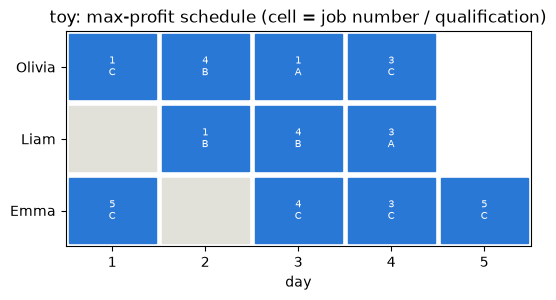

In [19]:
gantt(INST["toy"], best["toy"][1], "toy: max-profit schedule (cell = job number / qualification)")

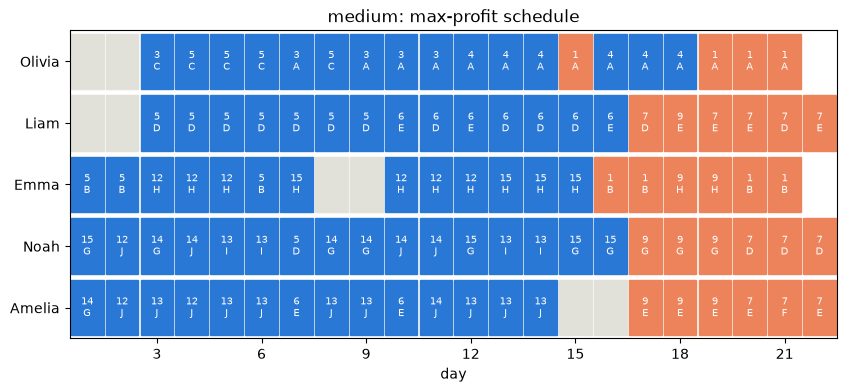

In [20]:
gantt(INST["medium"], best["medium"][1], "medium: max-profit schedule")

## 4b. Proof that the maximum profit is optimal

CP-SAT reports `OPTIMAL`, but you should not have to trust a solver log. Here is an **independent, checkable
certificate** in three steps.

1. **Net profit ≤ gross gain.** Penalties are never negative, so any schedule's profit is at most the sum of the
   gains of the projects it delivers.
2. **Which project sets can be staffed at all?** Ignoring due dates, a set of projects can be staffed *iff* for every
   skill subset $S$: demand$(S)\le$ days of employees holding a skill in $S$ (Hall's theorem). A depth-first search lists
   **every** such set whose gross gain beats the best profit found. Nothing outside the list can win.
3. **Kill each candidate.** For each listed set $P$ we ask CP-SAT: *can $P$ be staffed with total lateness
   penalty $\le$ gross$(P)-$best$-1$?* `INFEASIBLE` means $P$ cannot beat the best. If every set is infeasible, the best
   profit is the maximum. The sub-models are tiny (only the projects of $P$), so this is much faster than proving
   optimality on the full model.

If the search *finds* a feasible set, it has found a better schedule, the best is raised, and the search continues.

In [21]:
SET_TL = 60  # seconds allowed for each candidate set; raise it if a set stays UNKNOWN


def candidate_sets(I, inc):
    """All project sets that pass every Hall inequality and have gross gain > inc (sorted by gain, best first)."""
    jobs = sorted(I["jobs"], key=lambda j: -j["gain"])
    subsets, caps = hall_data(I)
    need = [[sum(v for q, v in j["req"].items() if q in S) for S in subsets] for j in jobs]
    rest = [0] * (len(jobs) + 1)
    for k in range(len(jobs) - 1, -1, -1):
        rest[k] = rest[k + 1] + jobs[k]["gain"]
    out = []

    def dfs(k, gain, use, chosen):
        if gain + rest[k] <= inc:
            return  # even taking every remaining job cannot beat inc
        if k == len(jobs):
            return out.append((gain, tuple(chosen)))
        nxt = [a + b for a, b in zip(use, need[k])]
        if all(a <= c for a, c in zip(nxt, caps)):
            dfs(k + 1, gain + jobs[k]["gain"], nxt, [*chosen, jobs[k]["name"]])
        dfs(k + 1, gain, use, chosen)

    dfs(0, 0, [0] * len(subsets), [])
    return sorted(out, key=lambda t: -t[0])

In [22]:
def staff_set(I, names, cap, tl):
    """Staff exactly the jobs `names` with total lateness penalty <= cap. Returns (status, penalty, schedule)."""
    m, h, x = cp_model.CpModel(), I["horizon"], {}
    for s in I["staff"]:
        for jn in names:
            for q in I["J"][jn]["req"]:
                if q in s["qualifications"]:
                    for t in I["days"]:
                        if t not in s["vacations"]:
                            x[s["name"], jn, q, t] = m.new_bool_var("")
    for xs in group(x, lambda k: (k[0], k[3])).values():
        m.add_at_most_one(xs)
    by_jq, by_jt = group(x, lambda k: (k[1], k[2])), group(x, lambda k: (k[1], k[3]))
    for jn in names:
        for q, n in I["J"][jn]["req"].items():
            m.add(sum(by_jq[jn, q]) == n)
    cost = []
    for jn in names:
        d, p = I["J"][jn]["due_date"], I["J"][jn]["daily_penalty"]
        if d < h:
            late = m.new_int_var(0, h - d, "")
            for t in range(d + 1, h + 1):
                for v in by_jt.get((jn, t), []):
                    m.add(late >= t - d).only_enforce_if(v)
            cost.append(p * late)
    total = sum(cost) if cost else 0
    m.add(total <= cap)
    m.minimize(total)
    sv = cp_model.CpSolver()
    sv.parameters.max_time_in_seconds, sv.parameters.num_workers = tl, WORKERS
    status = sv.status_name(sv.solve(m))
    if status not in ("OPTIMAL", "FEASIBLE"):
        return status, None, None
    sched = {(i, t): (j, q) for (i, j, q, t), v in x.items() if sv.value(v)}
    return status, evaluate_penalty(I, sched), sched


def evaluate_penalty(I, sched):
    last = {}
    for (_, t), (j, _) in sched.items():
        last[j] = max(last.get(j, 0), t)
    return sum(I["J"][j]["daily_penalty"] * max(0, t - I["J"][j]["due_date"]) for j, t in last.items())

In [23]:
HARD_TL = 240  # seconds for the sets that stay UNKNOWN after the normal pass (retried once)


def prove_max_profit(I, start, tl=SET_TL, hard_tl=HARD_TL):
    """Certificate that no schedule has profit > the best one found. `start` is only a lower bound used to prune:
    the search re-finds the optimum itself, so a wrong or low `start` cannot produce a wrong answer.
    Pass 1 (short limits) raises the incumbent fast; pass 2 re-lists the candidate sets above it and kills them
    with the normal limit; pass 3 retries the sets still UNKNOWN with a long limit. Returns dict(profit, schedule,
    certified, table, trace)."""
    t0, st = time.time(), {"inc": start - 1, "best": None, "trace": [], "rows": []}

    def run(sets, limit):
        unknown = []
        for gross, names in sets:
            while gross > st["inc"]:
                t = time.time()
                status, pen, sched = staff_set(I, names, gross - st["inc"] - 1, limit)
                st["rows"].append({"gross": gross, "jobs": len(names), "status": status,
                                   "seconds": time.time() - t, "cap": gross - st["inc"] - 1, "pass": limit})
                if status == "INFEASIBLE":
                    break
                if status not in ("OPTIMAL", "FEASIBLE"):
                    unknown.append((gross, names))
                    break
                st["inc"], st["best"] = gross - pen, sched
                st["trace"].append((time.time() - t0, st["inc"]))
                if status == "OPTIMAL":
                    break  # penalty minimised: this set cannot do better than the incumbent
                unknown.append((gross, names))  # FEASIBLE only: the set is not yet certified
                break
        return unknown

    run(candidate_sets(I, st["inc"]), max(2, tl // 6))          # pass 1: quick, raises the incumbent
    n_sets = len(candidate_sets(I, st["inc"]))
    left = run(candidate_sets(I, st["inc"]), tl)                 # pass 2: normal limit
    left = run(left, hard_tl) if left else []                    # pass 3: retry what is left, long limit
    table = pd.DataFrame(st["rows"])
    last = table[table["pass"] == table["pass"].max()] if len(table) else table
    return {"profit": st["inc"], "schedule": st["best"], "certified": not left, "table": table,
            "trace": st["trace"], "n_sets": n_sets, "unresolved": left, "seconds": time.time() - t0}

### Run the certificate on the three instances

`start` is the heuristic profit from section 4 (a lower bound only). The final profit must come out of the
certificate itself, checked by the independent `evaluate`.

In [24]:
proof = {}
for n, I in INST.items():
    proof[n] = prove_max_profit(I, best[n][1]["profit"])
    p = proof[n]
    p["checked"] = evaluate(I, p["schedule"])["profit"] if p["schedule"] else 0
pd.DataFrame(
    {
        n: {
            "CP-SAT 30 s": best[n][1]["profit"],
            "certificate profit": p["profit"],
            "independent evaluate": p["checked"],
            "candidate sets": p["n_sets"],
            "sub-solves": len(p["table"]),
            "unresolved sets": len(p["unresolved"]),
            "certified optimal": p["certified"],
            "seconds": round(p["seconds"], 1),
        }
        for n, p in proof.items()
    }
)

,toy,medium,large
CP-SAT 30 s,65,413,817
certificate profit,65,413,817
independent evaluate,65,413,817
candidate sets,1,38,775
sub-solves,4,76,1550
unresolved sets,0,0,0
certified optimal,True,True,True
seconds,0.0,3.1,95.6


### Plots that defend the answer

*Left:* the proof ladder. The trivial bound (every project) is far above; the Hall bound (best set that fits the
capacity) is much closer; the proven maximum is the last rung. *Middle:* each dot is one candidate project set above
the best profit, and each was killed (`INFEASIBLE`). *Right:* how the best profit grew during the search.

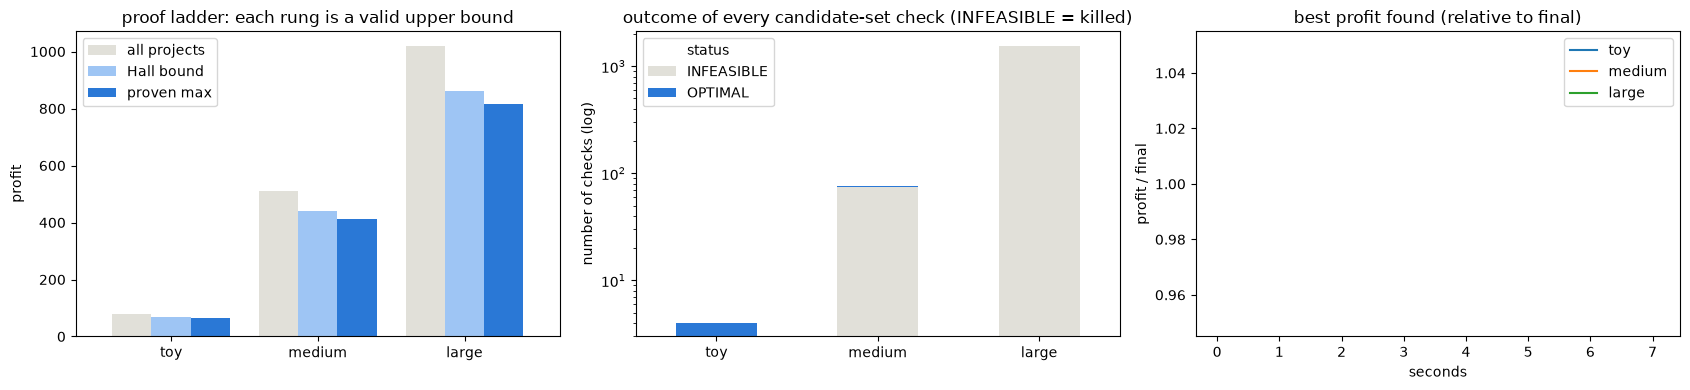

In [25]:
def hall_bound(I):
    """Largest gross gain of any project set passing all Hall inequalities (a tiny knapsack, solved exactly)."""
    m = cp_model.CpModel()
    y = {j: m.new_bool_var("") for j in I["J"]}
    for S, cap in zip(*hall_data(I)):
        m.add(sum(sum(n for q, n in I["J"][j]["req"].items() if q in S) * y[j] for j in y) <= cap)
    m.maximize(sum(I["J"][j]["gain"] * y[j] for j in y))
    s = cp_model.CpSolver()
    s.solve(m)
    return round(s.objective_value)


ladder = pd.DataFrame(
    {n: {"all projects": sum(j["gain"] for j in I["jobs"]), "Hall bound": hall_bound(I), "proven max": proof[n]["profit"]}
     for n, I in INST.items()}
).T
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ladder.plot.bar(ax=ax[0], color=[GREY, LIGHT, BLUE], rot=0, width=0.8)
ax[0].set(title="proof ladder: each rung is a valid upper bound", ylabel="profit")
outcome = pd.DataFrame({n: p["table"].status.value_counts() for n, p in proof.items()}).fillna(0).T
outcome.plot.bar(ax=ax[1], stacked=True, logy=True, rot=0, color={"INFEASIBLE": GREY, "OPTIMAL": BLUE, "FEASIBLE": LIGHT, "UNKNOWN": ORANGE})
ax[1].set(title="outcome of every candidate-set check (INFEASIBLE = killed)", ylabel="number of checks (log)")
for n, p in proof.items():
    if p["trace"]:
        ts, vs = zip(*p["trace"])
        ax[2].step(ts, [v / max(vs) for v in vs], where="post", label=n)
ax[2].set(title="best profit found (relative to final)", xlabel="seconds", ylabel="profit / final")
ax[2].legend()
fig.tight_layout()

In [26]:
pd.DataFrame(
    {n: p["table"].groupby("status").agg(sets=("gross", "size"), seconds=("seconds", "sum")).round(1).stack()
     for n, p in proof.items()}
).fillna(0)  # how many sub-solves ended INFEASIBLE / found a better schedule / ran out of time

toy  medium   large
status                                 
INFEASIBLE sets     3.0    75.0  1549.0
           seconds  0.0     3.0    90.8
OPTIMAL    sets     1.0     1.0     1.0
           seconds  0.0     0.0     0.1

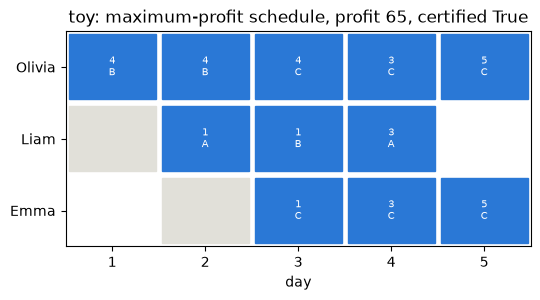

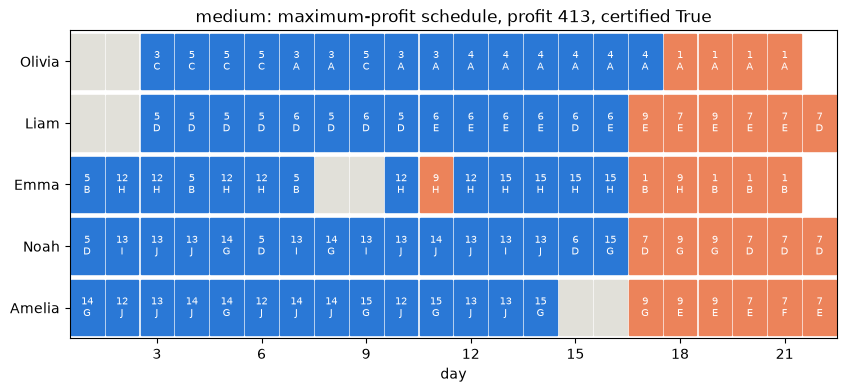

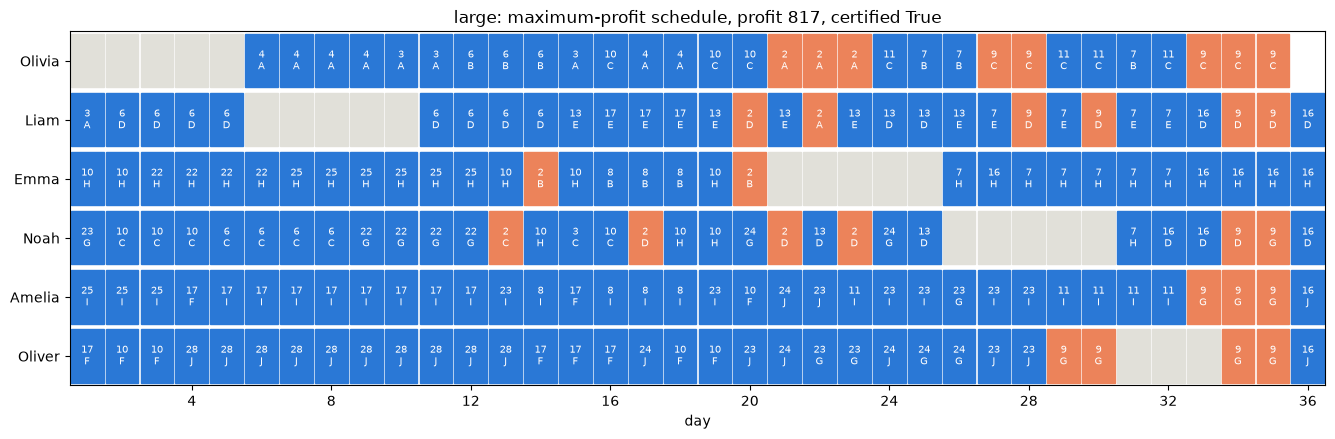

In [27]:
for n, I in INST.items():
    p = proof[n]
    gantt(I, {"schedule": p["schedule"]}, f"{n}: maximum-profit schedule, profit {p['checked']}, certified {p['certified']}")

**Reading the certificate.** `certified optimal = True` means every candidate set passed `INFEASIBLE` or
`OPTIMAL`, none timed out, and the profit equals the independent `evaluate`. A `False` means at least one set
returned `UNKNOWN` (see the status table). Raise `SET_TL` or `WORKERS` and rerun; the profit shown is still a valid
schedule, but only a certified run proves it is the maximum.

## 5. Pareto methods

* **ε-constraint** (textbook, two objectives): maximise profit subject to $f\le\varepsilon$, then
  set $\varepsilon=f-1$ and repeat until infeasible.
* **Disjunctive exclusion** (any number of objectives): after each point $p$, add the constraint
  "beat $p$ strictly on at least one objective". The search stops when the model is infeasible.

Both are **exact** when every solve is proven optimal and the search ends infeasible. That case is
reported as `exact = True`. If the time budget runs out, the result is a set of valid,
mutually non-dominated schedules, and `proven` marks the points that are guaranteed Pareto-optimal.

In [28]:
def key(p, objs):
    return tuple(SENSE[o] * p[o] for o in objs)


def dominates(a, b):
    return a != b and all(x <= y for x, y in zip(a, b, strict=True))


def nondominated(points, objs):
    pts = {key(p, objs): p for p in sorted(points, key=lambda p: p["proven"])}  # proven copy wins
    return [pts[k] for k in sorted(pts) if not any(dominates(o, k) for o in pts)]


def finish(front, objs, status):
    exact = status == "INFEASIBLE" and all(p["proven"] for p in front)
    return nondominated(front, objs), exact

In [29]:
def epsilon_2d(I, obj, tl=TL, budget=BUDGET):
    objs, t0, front, status = ["profit", obj], time.time(), [], "UNKNOWN"
    M = build(I, objs)
    while (left := budget - (time.time() - t0)) > 0:
        status, p = solve(M, I, objs, min(tl, left), hint=front[-1]["schedule"] if front else None)
        if p is None:
            break
        front.append(p)
        if p[obj] == M.dom[obj][0]:  # nothing below the minimum: done
            status = "INFEASIBLE"
            break
        M.m.proto.variables[M.v[obj].index].domain[1] = p[obj] - 1  # epsilon = f - 1
    return finish(front, objs, status)

In [30]:
def pareto(I, objs, tl=TL, budget=BUDGET):
    M, t0, front, status = build(I, objs), time.time(), [], "UNKNOWN"
    while (left := budget - (time.time() - t0)) > 0:
        status, p = solve(M, I, objs, min(tl, left), hint=front[-1]["schedule"] if front else None)
        if p is None:
            break
        front.append(p)
        lits = [M.m.new_bool_var("") for _ in objs]
        for o, lit in zip(objs, lits, strict=True):  # beat p strictly on some objective
            M.m.add(SENSE[o] * M.v[o] <= SENSE[o] * p[o] - 1).only_enforce_if(lit)
        M.m.add_bool_or(lits)
    return finish(front, objs, status)

In [31]:
def table(front, objs=OBJS):
    return pd.DataFrame(front)[[*objs, "proven"]]


def payoff(front, objs, min_profit):
    """Best point for each objective among the points at or above a reservation profit."""
    df = table(front, objs)
    df = df[df.profit >= min_profit]
    return pd.DataFrame({o: df.loc[(SENSE[o] * df[o]).idxmin(), objs] for o in objs}).T

In [32]:
def plot_2d(front, obj, ax, title=""):
    """Faint dots: every point. Staircase: the points that are non-dominated in this 2D view."""
    df, nd = table(front), table(nondominated(front, ["profit", obj])).sort_values(obj)
    ax.scatter(df[obj], df.profit, color=LIGHT, s=15, zorder=1)
    ax.step(nd[obj], nd.profit, where="post", color=GREY, zorder=2)
    ax.scatter(
        nd[obj], nd.profit, c=[BLUE if p else "white" for p in nd.proven], edgecolors=BLUE, zorder=3
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, min_n_ticks=1))
    ax.set_xlim(df[obj].min() - 0.5, df[obj].max() + 0.5)
    ax.set(xlabel=obj, ylabel="profit", title=title)
    ax.grid(color=GREY, lw=0.5)


def parallel(front, objs=OBJS):
    df = table(front, objs)[objs]
    ax = ((df - df.min()) / (df.max() - df.min()).replace(0, 1)).T.plot(
        legend=False, color=BLUE, alpha=0.35, figsize=(9, 4)
    )
    ax.set(ylabel="value scaled to [0, 1] on the front", title="one line = one Pareto point")

## 6. Toy instance: exact fronts

### Check: both methods give the same front for every pair (profit, X)

In [33]:
toy = INST["toy"]
check = {o: (epsilon_2d(toy, o), pareto(toy, ["profit", o])) for o in OBJS[1:]}
pd.DataFrame(
    {
        o: {
            "points": len(e[0]),
            "both exact": e[1] and d[1],
            "same front": [key(p, ["profit", o]) for p in e[0]]
            == [key(p, ["profit", o]) for p in d[0]],
        }
        for o, (e, d) in check.items()
    }
)

,duration,projects_per_staff,late_jobs,team_size,imbalance
points,3,3,1,3,6
both exact,True,True,True,True,True
same front,True,True,True,True,True


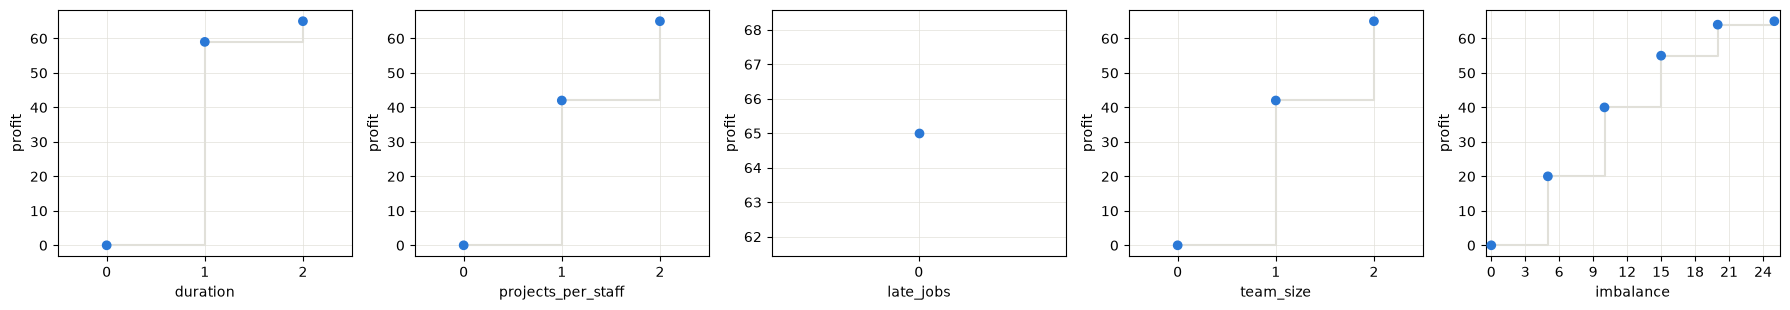

In [34]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, (o, ((front, _), _)) in zip(axes, check.items(), strict=True):
    plot_2d(front, o, ax)
fig.tight_layout()

### The brief's four objectives

In [35]:
front4, exact4 = pareto(toy, BRIEF)
print(len(front4), "Pareto points, exact:", exact4)
table(front4)

13 Pareto points, exact: True


,profit,duration,projects_per_staff,late_jobs,team_size,imbalance,proven
0,65,2,3,0,2,25,True
1,65,3,2,0,2,25,True
2,59,1,4,1,3,25,True
3,55,2,2,0,2,15,True
4,49,1,3,1,3,15,True
5,45,1,3,0,3,25,True
6,42,3,1,1,1,25,True
7,40,3,1,0,2,35,True
8,37,1,2,1,3,10,True
9,35,1,2,0,3,10,True


In [36]:
payoff(front4, BRIEF, min_profit=1)  # row = point that is best for that objective (profit > 0)

,profit,duration,projects_per_staff,late_jobs
profit,65,2,3,0
duration,59,1,4,1
projects_per_staff,42,3,1,1
late_jobs,65,2,3,0


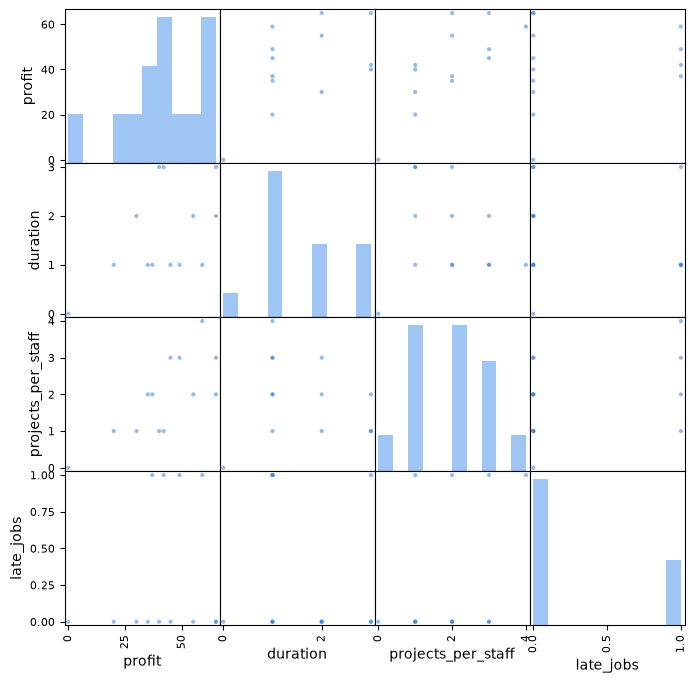

In [37]:
pd.plotting.scatter_matrix(
    table(front4)[BRIEF].astype(float), figsize=(8, 8), color=BLUE, hist_kwds={"color": LIGHT}
);

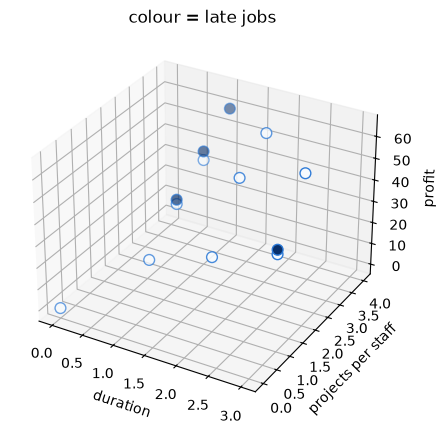

In [38]:
ax = plt.figure(figsize=(6, 5)).add_subplot(projection="3d")
df = table(front4)
ax.scatter(
    df.duration,
    df.projects_per_staff,
    df.profit,
    c=df.late_jobs,
    cmap="Blues",
    edgecolors=BLUE,
    s=60,
)
ax.set(xlabel="duration", ylabel="projects per staff", zlabel="profit", title="colour = late jobs");

### All six objectives, and do they really conflict?

Spearman correlation over the Pareto points, with every objective oriented "smaller is better".
Negative means the two objectives conflict; close to +1 means they are redundant.

In [39]:
front6, exact6 = pareto(toy, OBJS)
print(len(front6), "Pareto points, exact:", exact6)
(table(front6)[OBJS] * pd.Series(SENSE)).corr("spearman").round(2)

18 Pareto points, exact: True


,profit,duration,projects_per_staff,late_jobs,team_size,imbalance
profit,1.00,-0.33,-0.81,-0.37,-0.29,-0.11
duration,-0.33,1.00,-0.15,-0.11,-0.50,0.63
projects_per_staff,-0.81,-0.15,1.00,0.44,0.63,-0.07
late_jobs,-0.37,-0.11,0.44,1.00,0.27,-0.12
team_size,-0.29,-0.50,0.63,0.27,1.00,-0.35
imbalance,-0.11,0.63,-0.07,-0.12,-0.35,1.00


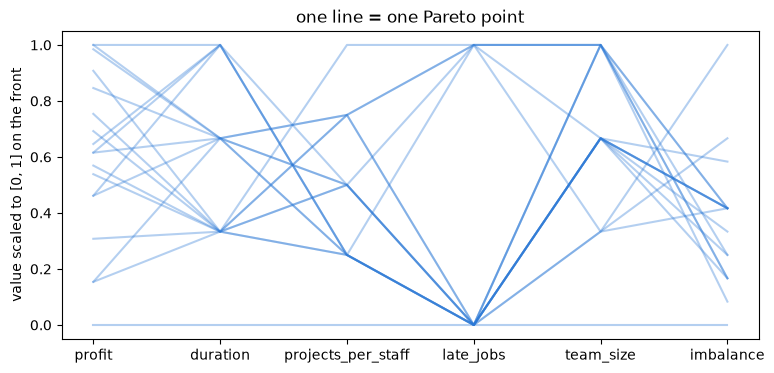

In [40]:
parallel(front6)

### Decision space: pick any Pareto point

In [41]:
_ = interact(
    lambda k: gantt(toy, front4[k], str({o: front4[k][o] for o in BRIEF})), k=(0, len(front4) - 1)
)

interactive(children=(IntSlider(value=6, description='k', max=12), Output()), _dom_classes=('widget-interact',…

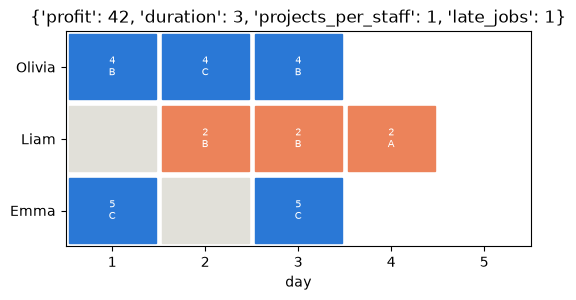

In [42]:
gantt(toy, front4[len(front4) // 2], str({o: front4[len(front4) // 2][o] for o in BRIEF}))

## 7. Medium instance: four objectives under a time budget

In [43]:
medium = INST["medium"]
front_m, exact_m = pareto(medium, BRIEF, budget=3 * BUDGET)
print(
    len(front_m),
    "points;",
    sum(p["proven"] for p in front_m),
    "proven Pareto-optimal; exact:",
    exact_m,
)
table(front_m).head(15)

30 points; 2 proven Pareto-optimal; exact: False


,profit,duration,projects_per_staff,late_jobs,team_size,imbalance,proven
0,413,8,6,3,4,5,True
1,413,10,5,3,4,5,True
2,411,6,7,2,4,10,False
3,411,7,6,2,4,10,False
4,410,8,5,3,4,10,False
5,410,9,5,2,4,5,False
6,408,8,6,1,4,10,False
7,408,9,5,1,3,10,False
8,406,5,7,2,4,10,False
9,405,6,6,3,4,5,False


In [44]:
reservation = int(0.7 * best["medium"][1]["profit"])  # CEO: at least 70 % of the max profit
payoff(front_m, BRIEF, reservation)

,profit,duration,projects_per_staff,late_jobs
profit,413,8,6,3
duration,406,5,7,2
projects_per_staff,381,12,3,1
late_jobs,400,8,5,0


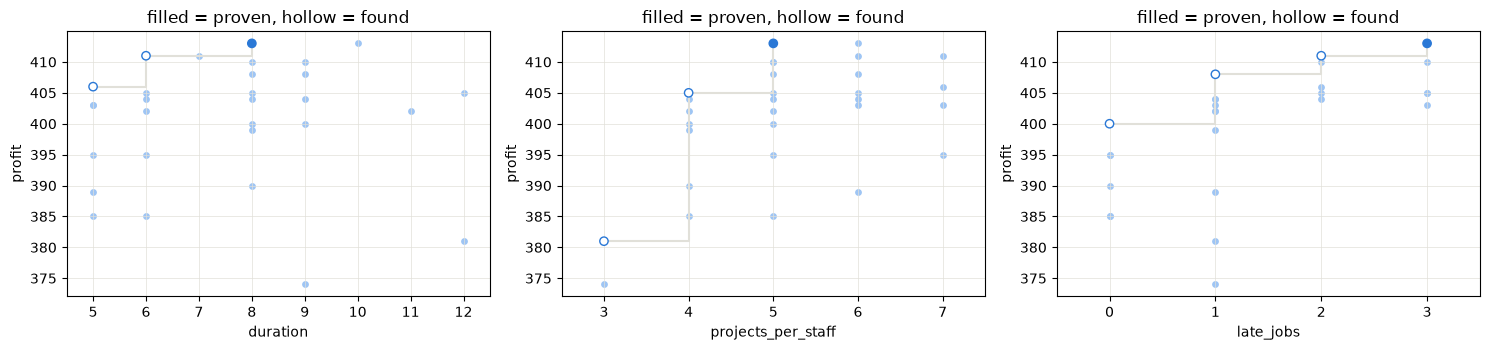

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, o in zip(axes, BRIEF[1:], strict=True):
    plot_2d(front_m, o, ax, "filled = proven, hollow = found")
fig.tight_layout()

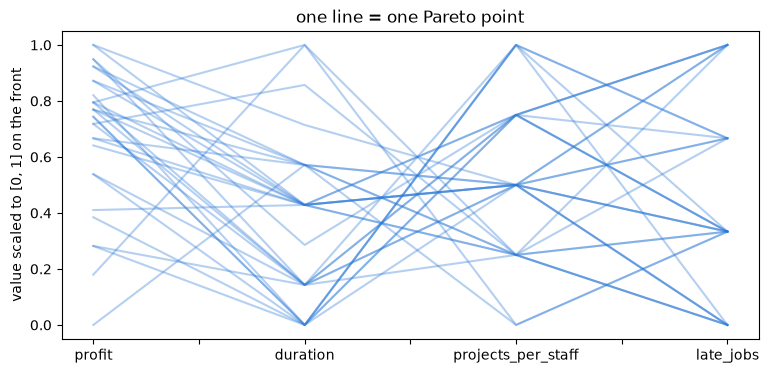

In [46]:
parallel(front_m, BRIEF)

In [47]:
_ = interact(
    lambda k: gantt(medium, front_m[k], str({o: front_m[k][o] for o in BRIEF})),
    k=(0, len(front_m) - 1),
)

interactive(children=(IntSlider(value=14, description='k', max=29), Output()), _dom_classes=('widget-interact'…

## 8. Large instance: profit against each other objective

In [48]:
large = INST["large"]
fronts_l = {o: pareto(large, ["profit", o]) for o in OBJS[1:]}
pd.DataFrame(
    {
        o: {"points": len(f), "proven": sum(p["proven"] for p in f), "exact": ex}
        for o, (f, ex) in fronts_l.items()
    }
)

,duration,projects_per_staff,late_jobs,team_size,imbalance
points,8,6,3,6,4
proven,0,0,0,0,0
exact,False,False,False,False,False


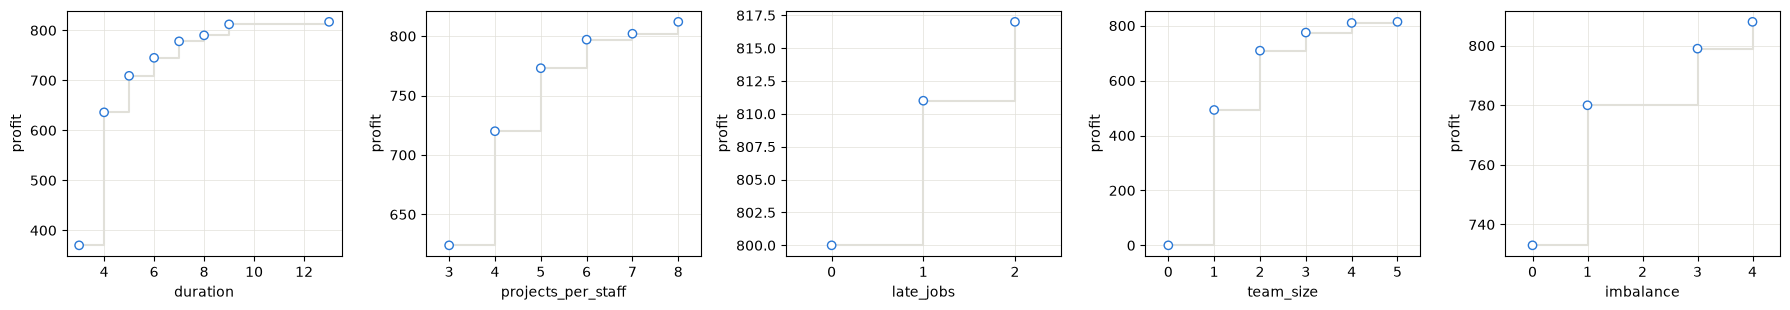

In [49]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, (o, (front, _)) in zip(axes, fronts_l.items(), strict=True):
    plot_2d(front, o, ax)
fig.tight_layout()

In [50]:
table(fronts_l["imbalance"][0], ["profit", "imbalance"])  # what does fairness cost?

,profit,imbalance,proven
0,808,4,False
1,799,3,False
2,780,1,False
3,733,0,False


## 9. Instance generator

Same JSON format as the given files. Gains grow with workload and urgency, as in the provided data.
Each employee gets one holiday block. `load` sets the demand/capacity ratio, and the generator redraws
until demand exceeds capacity, so that, as in the real data, not every project fits. The seed makes
every instance reproducible.

In [51]:
def gen_staff(rnd, h, n, Q):
    staff = []
    for i in range(n):
        start, length = rnd.randint(1, h), rnd.randint(0, 3)
        staff.append(
            {
                "name": f"S{i + 1}",
                "qualifications": rnd.sample(Q, rnd.randint(2, min(4, len(Q)))),
                "vacations": [t for t in range(start, start + length) if t <= h],
            }
        )
    return staff

In [52]:
def gen_jobs(rnd, h, n, held, per_job):
    # per_job = target person-days per job (on average)
    jobs = []
    for j in range(n):
        quals = rnd.sample(held, rnd.randint(1, min(3, len(held))))
        top = min(h // 2, max(1, round(2 * per_job / len(quals)) - 1))
        req = {q: rnd.randint(1, top) for q in quals}
        due = rnd.randint(h // 3, h)
        gain = 5 * round((3.3 * sum(req.values()) + 52 * (1 - due / h) - 13 + rnd.gauss(0, 8)) / 5)
        jobs.append(
            {
                "name": f"Job{j + 1}",
                "gain": max(5, gain),
                "due_date": due,
                "daily_penalty": 3,
                "working_days_per_qualification": req,
            }
        )
    return jobs

In [53]:
def generate(h=15, n_staff=4, n_jobs=9, n_quals=5, seed=0, load=1.3):
    # load = target demand / capacity; redraw until demand > capacity, as in the given data
    rnd, Q = random.Random(seed), [chr(65 + k) for k in range(n_quals)]
    while True:
        staff = gen_staff(rnd, h, n_staff, Q)
        cap = sum(h - len(s["vacations"]) for s in staff)
        held = sorted({q for s in staff for q in s["qualifications"]})
        jobs = gen_jobs(rnd, h, n_jobs, held, load * cap / n_jobs)
        if sum(sum(j["working_days_per_qualification"].values()) for j in jobs) > cap:
            return {"horizon": h, "qualifications": Q, "staff": staff, "jobs": jobs}

In [54]:
raw = generate(seed=1)
Path("results/generated").mkdir(parents=True, exist_ok=True)
Path("results/generated/h15_s4_j9_seed1.json").write_text(json.dumps(raw, indent=1))
gen = prepare(json.loads(json.dumps(raw)), "h15_s4_j9_seed1")  # round-trip through JSON
front_g, exact_g = pareto(gen, BRIEF)
print(stats(gen), "|", len(front_g), "Pareto points, exact:", exact_g)

{'days': 15, 'staff': 4, 'jobs': 9, 'x variables': 682, 'demand / capacity': 1.42} | 38 Pareto points, exact: True


### Scaling: how fast does the exact front get harder? (profit vs longest project)

In [55]:
rows = []
for h, s, j in [(10, 3, 6), (15, 4, 9), (20, 5, 12)]:
    for seed in range(2):
        I, t0 = prepare(generate(h, s, j, max(4, j // 2), seed)), time.time()
        front, exact = pareto(I, ["profit", "duration"], budget=60)
        rows.append(
            {
                **stats(I),
                "seed": seed,
                "points": len(front),
                "exact": exact,
                "seconds": round(time.time() - t0, 1),
            }
        )
bench = pd.DataFrame(rows)
bench

,days,staff,jobs,x variables,demand / capacity,seed,points,exact,seconds
0,10,3,6,262,1.04,0,3,True,0.0
1,10,3,6,221,1.07,1,4,True,0.1
2,15,4,9,864,1.22,0,5,True,5.3
3,15,4,9,721,1.21,1,6,True,0.2
4,20,5,12,1348,1.13,0,7,True,0.7
5,20,5,12,1158,1.33,1,10,True,8.2


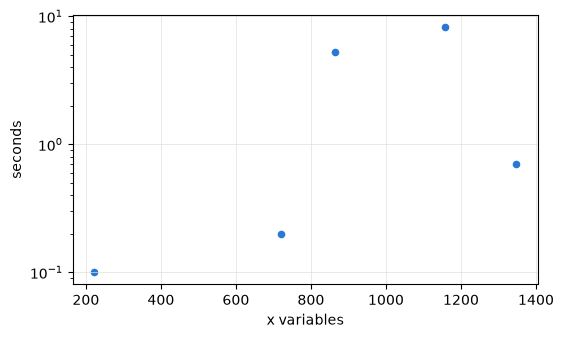

In [56]:
ax = bench.plot.scatter("x variables", "seconds", color=BLUE, logy=True, figsize=(6, 3.5))
ax.grid(color=GREY, lw=0.5)

## 10. Verification: compare with brute force

On tiny generated instances (3 days, 2 employees, 3 jobs) we can list **every** possible schedule:
each free employee-day is either idle or one legal task. We keep the feasible schedules, filter the
non-dominated ones, and compare them with the solver's front.

In [57]:
def all_feasible(I):
    cells = [(s["name"], t) for s in I["staff"] for t in I["days"] if t not in s["vacations"]]
    opts = [[None] + [(j, q) for i, j, q, t in I["slots"] if (i, t) == c] for c in cells]
    found = []
    for choice in itertools.product(*opts):
        with contextlib.suppress(AssertionError):  # schedule breaks a rule
            found.append(
                {
                    **evaluate(I, {c: o for c, o in zip(cells, choice, strict=True) if o}),
                    "proven": True,
                }
            )
    return found

In [58]:
ok = []
for seed in range(10):
    I = prepare(generate(h=3, n_staff=2, n_jobs=3, n_quals=2, seed=seed))
    every = all_feasible(I)
    for objs in (BRIEF, OBJS):
        front, exact = pareto(I, objs)
        ok.append(
            exact
            and [key(p, objs) for p in front] == [key(p, objs) for p in nondominated(every, objs)]
        )
print(f"solver front == brute-force front on {sum(ok)} / {len(ok)} (instance, objective set) pairs")

solver front == brute-force front on 20 / 20 (instance, objective set) pairs


## 11. Conclusions

*Numbers below are from the run saved in this notebook (14 CPU threads, about 16 minutes in total).
Medium and large fronts are time-limited, so they can shift slightly between runs.*

* **Maximum profit, certified:** 65 (toy), 413 (medium), 817 (large). CP-SAT finds each in 30 s, and the
  certificate of section 4b proves it independently: Hall's theorem leaves 1 / 38 / 775 candidate project
  sets that could beat the best plan, and a small CP-SAT check rules out every one of them
  (< 0.1 s / 3 s / 96 s). The certified plans pass the independent `evaluate`.
* **Toy is solved exactly:** 13 Pareto-optimal schedules for the brief's four objectives and 18 with all
  six. The ε-constraint and disjunctive methods return identical fronts on every pair.
* **Trade-offs a manager can act on (medium, 30 plans found, 2 proven):** the max-profit plan (413)
  delivers 3 projects late. Giving up 3.1 % of profit (400) removes all lateness, 1.7 % (406) caps the
  longest project at 5 days, and 7.7 % (381) keeps every employee on at most 3 projects.
* **Large:** removing all lateness costs 2.1 % (800 vs 817); short projects or at most 3 projects per
  employee cost over 20 %. Fairness is the least stable pair with 2 minutes: the best fully fair plan
  found was 733 in this run and has ranged from 628 to 800 across our runs.
* **Which objectives really conflict (toy, Spearman):** profit vs projects per employee is the strongest
  conflict (−0.81). Of our extras, team size conflicts with duration (−0.50): small teams take longer.
  Fairness conflicts with team size (−0.35) but hardly with profit (−0.11). Every instance is over
  capacity, so at maximum profit almost everyone is already busy.
* **Verified:** the solver's front equals the brute-force front on 20 / 20 tiny cases (section 10).
* **Doing nothing is always Pareto-optimal**, because every minimised objective improves by doing less.
  The payoff tables therefore use a reservation profit.
* **Limits:** finding good schedules is fast, but *proving* there is no better one is slow. Exact fronts
  with several objectives on medium/large take hours. With the default budget, those fronts are valid,
  mutually non-dominated schedules, and `proven` marks the guaranteed Pareto-optimal points.
* **Generator:** generated instances up to about 1,400 decision variables get an exact two-objective
  front in under 10 s.
* **Figures:** section 12 draws the presentation figures and exports the six key ones to `docs/figures/`
  (PNG + vector PDF).

## 12. Figures for the report and slides

One consistent style for every figure. The six key figures are saved twice in `docs/figures/`: PNG
for the README and slides, PDF (vector) for the LaTeX report; the others are only shown here.
Instance colours stay fixed everywhere: toy blue, medium orange, large green.

In [59]:
FIG = Path("docs/figures")
FIG.mkdir(parents=True, exist_ok=True)
INST_COLOR = {"toy": BLUE, "medium": "#eb6834", "large": "#1baf7a"}  # colour-blind-safe trio
INK, INK2, MUTED, AXIS = "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
LABEL = {"profit": "profit", "duration": "longest project (days)",
         "projects_per_staff": "max projects per employee", "late_jobs": "late projects",
         "team_size": "largest team", "imbalance": "utilisation gap (% points)"}
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GREY, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "savefig.facecolor": "white",
})


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200, bbox_inches="tight")